# Atropelamentos em São Paulo (2022–2025): o que aumenta a chance de morte?

**Pré-requisito:** rodar antes o notebook `01_limpeza_analise_atropelamentos_sp.ipynb`, que gera as bases em
`data/processed/`.

**Pergunta:** no notebook 01 vimos que idosos e o turno da noite concentram as mortes. Mas esses fatores podem
estar misturados: talvez os idosos morram mais só porque são atropelados em horários ou vias mais perigosos.
Este notebook separa os efeitos com uma **regressão logística**.

**Unidade de análise:** o **pedestre vítima** (cada pessoa atropelada).
**Variável resposta:** `obito` (morreu em até 30 dias = 1; sobreviveu = 0).

**Variáveis explicativas e categorias de referência**

| Variável | Categorias | Referência | Por que essa referência |
|---|---|---|---|
| Faixa etária | 0-17 … 80+ | 30-39 | adulto em idade ativa, grupo grande e estável |
| Sexo | feminino, masculino | feminino | |
| Turno | madrugada, manhã, tarde, noite | tarde | turno de maior volume e menor letalidade |
| Tipo de via | vias urbanas, estradas e rodovias | vias urbanas | é onde está a maioria dos casos |
| Fim de semana | sim / não | não | |
| Ano do sinistro | 2022 … 2025 | 2022 | mede a tendência já descontando os outros fatores |

**Como ler o resultado:** cada fator aparece como **razão de chances** (*odds ratio*, OR). OR = 3 quer dizer que a
chance de morrer é cerca de 3 vezes a da categoria de referência, **mantendo as outras variáveis constantes**.
Quando o intervalo de 95% cruza o 1, o efeito não é distinguível de "nenhum efeito".

## 1. Base do modelo

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

def achar_raiz(inicio: Path = Path.cwd()) -> Path:
    for p in [inicio, *inicio.parents]:
        if (p / "data" / "raw").is_dir():
            return p
    raise FileNotFoundError("pasta data/raw não encontrada acima de " + str(inicio))
ROOT = achar_raiz()
PROCESSED = ROOT / "data" / "processed"

AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "#bdbcb6", "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
})

vit = pd.read_parquet(PROCESSED / "vitimas_pedestres_sp_2022_2025.parquet")
sin = pd.read_parquet(PROCESSED / "sinistros_sp_2022_2025.parquet")

df = vit.merge(sin[["id_sinistro", "turno", "tipo_via", "dia_da_semana"]].rename(columns={"tipo_via": "tipo_via_sinistro"}),
               on="id_sinistro", how="left")
df["obito"] = df["obito"].astype(int)
df["fim_de_semana"] = df["dia_da_semana"].isin(["Sábado", "Domingo"]).astype(int)
df["ano"] = df["ano_sinistro"].astype(str)
print(f"pedestres vítimas: {len(df):,} | óbitos: {df['obito'].sum():,} ({df['obito'].mean():.1%})")

pedestres vítimas: 19,382 | óbitos: 1,441 (7.4%)


### 1.1 Registros que saem do modelo
A regressão precisa de todas as variáveis preenchidas. Mostramos quantos casos saem por cada motivo e **quantos
deles são óbitos**, porque perder óbitos de forma desigual distorce o resultado.

In [2]:
motivos = {
    "faixa etária ausente": df["faixa_etaria"].isna(),
    "sexo ausente": df["sexo"].isna(),
    "turno ausente": df["turno"].isna(),
    "tipo de via ausente": df["tipo_via_sinistro"].isna(),
}
perdas = pd.DataFrame({m: {"vítimas": s.sum(), "óbitos": df.loc[s, "obito"].sum()} for m, s in motivos.items()}).T
qualquer = pd.concat(motivos, axis=1).any(axis=1)
perdas.loc["total (qualquer motivo)"] = [qualquer.sum(), df.loc[qualquer, "obito"].sum()]
perdas

,vítimas,óbitos
faixa etária ausente,200,178
sexo ausente,19,6
turno ausente,51,51
tipo de via ausente,115,115
total (qualquer motivo),334,304


**Atenção, a perda não é aleatória:** dos 334 casos que saem, **304 são óbitos**, cerca de 21% de todas as
mortes de pedestres. Idade, turno e tipo de via ausentes aparecem quase só em óbitos. Isso é coerente com
registros de morte que chegam por outra fonte, sem o boletim completo.

Consequências:
- a letalidade da base do modelo (~6%) fica **abaixo da real** (~7,4%), então as probabilidades da seção 3 são
  **conservadoras** (subestimadas);
- as razões de chances **entre grupos** continuam válidas se esses óbitos sem dados tiverem perfil parecido com o
  dos óbitos completos, o que não dá para verificar com esta base. Fica registrado como a principal limitação.

In [3]:
m = df[~qualquer].copy()
m["faixa_etaria"] = m["faixa_etaria"].astype(str)
print(f"base do modelo: {len(m):,} vítimas, {m['obito'].sum():,} óbitos ({m['obito'].mean():.1%})")

base do modelo: 19,048 vítimas, 1,137 óbitos (6.0%)


## 2. Modelo de regressão logística

In [4]:
FORMULA = ("obito ~ C(faixa_etaria, Treatment('30-39')) + C(sexo, Treatment('FEMININO'))"
           " + C(turno, Treatment('TARDE')) + C(tipo_via_sinistro, Treatment('VIAS URBANAS'))"
           " + fim_de_semana + C(ano, Treatment('2022'))")

modelo = smf.logit(FORMULA, data=m).fit(disp=False)
print(modelo.summary2().tables[0].to_string(header=False, index=False))

             Model:            Logit           Method:         MLE
Dependent Variable:            obito Pseudo R-squared:       0.121
              Date: 2026-11-11 22:10              AIC:   7604.6309
  No. Observations:            19048              BIC:   7738.1611
          Df Model:               16   Log-Likelihood:     -3785.3
      Df Residuals:            19031          LL-Null:     -4307.1
         Converged:           1.0000      LLR p-value: 5.3130e-212
    No. Iterations:           8.0000            Scale:      1.0000


In [5]:
def tabela_or(res):
    ci = res.conf_int()
    t = pd.DataFrame({"OR": np.exp(res.params), "IC95_inf": np.exp(ci[0]), "IC95_sup": np.exp(ci[1]),
                      "p_valor": res.pvalues}).drop(index="Intercept")
    # nomes legíveis: "C(turno, Treatment('TARDE'))[T.NOITE]" -> "turno: NOITE"
    t.index = (t.index.str.replace(r"C\((\w+),.*?\)\[T\.(.*)\]", r"\1: \2", regex=True)
                      .str.replace("fim_de_semana", "fim_de_semana: sim"))
    return t

ors = tabela_or(modelo)
ors.round({"OR": 2, "IC95_inf": 2, "IC95_sup": 2, "p_valor": 4})

,OR,IC95_inf,IC95_sup,p_valor
faixa_etaria: 0-17,0.75,0.52,1.07,0.1131
faixa_etaria: 18-29,0.68,0.52,0.91,0.0087
faixa_etaria: 40-49,1.36,1.06,1.75,0.0149
faixa_etaria: 50-59,2.50,1.97,3.17,0.0000
faixa_etaria: 60-69,3.45,2.71,4.40,0.0000
faixa_etaria: 70-79,7.02,5.47,8.99,0.0000
faixa_etaria: 80+,9.71,7.35,12.83,0.0000
sexo: MASCULINO,1.63,1.43,1.87,0.0000
turno: MADRUGADA,4.25,3.41,5.29,0.0000
turno: MANHA,1.13,0.94,1.35,0.1830


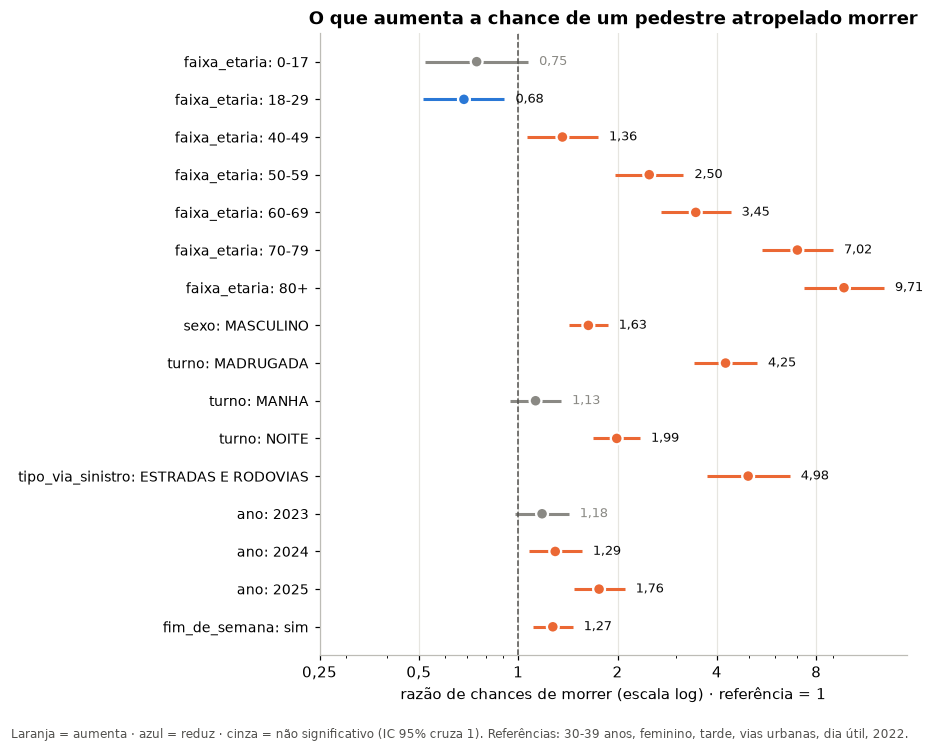

In [6]:
plot = ors.iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 6.8))
y = np.arange(len(plot))
sig = (plot["IC95_inf"] > 1) | (plot["IC95_sup"] < 1)
cores = np.where(plot["OR"] > 1, LARANJA, AZUL)
cores = np.where(sig, cores, CINZA)
ax.hlines(y, plot["IC95_inf"], plot["IC95_sup"], color=cores, lw=2)
ax.scatter(plot["OR"], y, color=cores, s=60, zorder=3, edgecolors="white", linewidths=1.5)
ax.axvline(1, color="#52514e", lw=1, ls="--")
ax.set_xscale("log")
ax.set_xticks([0.25, 0.5, 1, 2, 4, 8]); ax.set_xticklabels(["0,25", "0,5", "1", "2", "4", "8"])
ax.set_yticks(y); ax.set_yticklabels(plot.index, fontsize=9)
ax.grid(axis="y", visible=False)
for yi, (o, s) in enumerate(zip(plot["OR"], sig)):
    ax.text(plot["IC95_sup"].iloc[yi] * 1.08, yi, f"{o:.2f}".replace(".", ","), va="center", fontsize=8.5,
            color="#0b0b0b" if s else CINZA)
ax.set_xlabel("razão de chances de morrer (escala log) · referência = 1")
ax.set_title("O que aumenta a chance de um pedestre atropelado morrer")
fig.text(0.01, 0.005, "Laranja = aumenta · azul = reduz · cinza = não significativo (IC 95% cruza 1). "
         "Referências: 30-39 anos, feminino, tarde, vias urbanas, dia útil, 2022.", fontsize=8, color="#52514e")
fig.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

**Leitura:**
- **Idade** é o fator mais forte e cresce de forma contínua. A partir dos 60 anos a chance de morrer é várias
  vezes a de um adulto de 30-39, **mesmo comparando pessoas atropeladas no mesmo turno, tipo de via e ano**.
  Então o efeito dos idosos não é explicado por horário ou local: é a idade em si (fragilidade física).
- **Madrugada e noite** continuam elevando o risco depois de controlar pela idade. É o efeito de pouca luz e
  mais velocidade.
- **Estradas e rodovias** têm o maior efeito isolado do local: um atropelamento ali tende a ser em velocidade
  alta. A estimativa é **imprecisa** (poucos casos, intervalo largo e valor que muda bastante no teste da
  seção 4), então vale citar como "várias vezes maior", e não com um número exato.
- **Sexo masculino** aparece com chance maior. Pode refletir exposição diferente (horários, travessias em vias
  rápidas), e não fragilidade.
- O **ano** mostra se a letalidade subiu mesmo descontando os outros fatores. Lembre que 2025 tem não fatais
  ainda incompletos (notebook 01), então o coeficiente de 2025 deve estar inflado. Ver a seção 4.

## 3. Probabilidades previstas: traduzindo para números concretos
Razões de chances são difíceis de comunicar. Aqui o modelo estima a **probabilidade de morte** para perfis
típicos: pedestre em via urbana, dia útil, 2024, sexo masculino, variando idade e turno.

In [7]:
faixas = ["0-17", "18-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80+"]
turnos = ["MANHA", "TARDE", "NOITE", "MADRUGADA"]
grade = pd.DataFrame([(f, t) for f in faixas for t in turnos], columns=["faixa_etaria", "turno"])
grade = grade.assign(sexo="MASCULINO", tipo_via_sinistro="VIAS URBANAS", fim_de_semana=0, ano="2024")
grade["prob_obito_%"] = modelo.predict(grade) * 100
prev = grade.pivot(index="faixa_etaria", columns="turno", values="prob_obito_%").loc[faixas, turnos].round(1)
prev

turno,MANHA,TARDE,NOITE,MADRUGADA
faixa_etaria,,,,
0-17,1.9,1.7,3.3,6.7
18-29,1.7,1.5,3.0,6.2
30-39,2.5,2.2,4.3,8.8
40-49,3.4,3.0,5.8,11.6
50-59,6.0,5.4,10.1,19.4
60-69,8.1,7.3,13.5,25.0
70-79,15.2,13.7,24.0,40.4
80+,19.9,18.1,30.5,48.4


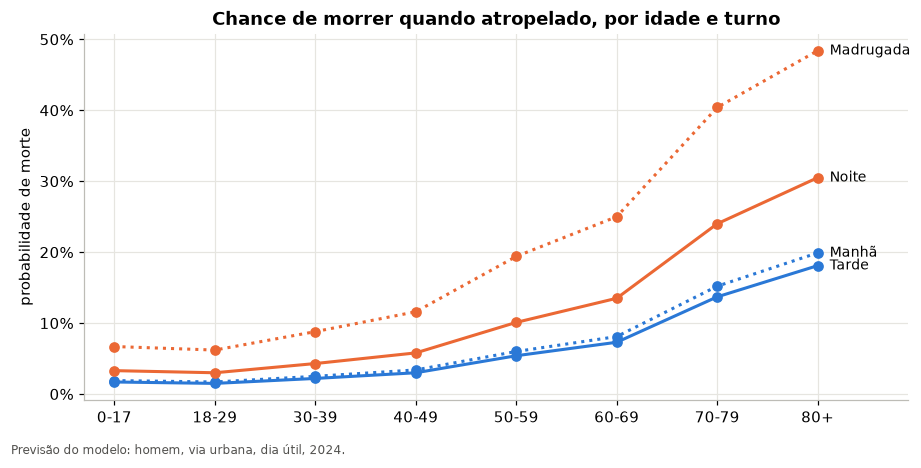

In [8]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
estilos = {"TARDE": (AZUL, "-"), "MANHA": (AZUL, ":"), "NOITE": (LARANJA, "-"), "MADRUGADA": (LARANJA, ":")}
x = np.arange(len(faixas))
for t in turnos:
    cor, ls = estilos[t]
    ax.plot(x, prev[t], color=cor, ls=ls, lw=2, marker="o", ms=6)
    ax.text(x[-1] + 0.12, prev[t].iloc[-1], t.capitalize().replace("Manha", "Manhã"), va="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(faixas)
ax.set_xlim(-0.3, len(faixas) - 0.1)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_ylabel("probabilidade de morte")
ax.set_title("Chance de morrer quando atropelado, por idade e turno")
fig.text(0.01, 0.005, "Previsão do modelo: homem, via urbana, dia útil, 2024.", fontsize=8, color="#52514e")
fig.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

In [9]:
p = lambda f, t: prev.loc[f, t]
print(f"Adulto 30-39 atropelado à tarde:      {p('30-39', 'TARDE'):.1f}%")
print(f"Idoso 70-79 atropelado à tarde:       {p('70-79', 'TARDE'):.1f}%  ({p('70-79', 'TARDE') / p('30-39', 'TARDE'):.1f}x)")
print(f"Idoso 70-79 atropelado de madrugada:  {p('70-79', 'MADRUGADA'):.1f}%  ({p('70-79', 'MADRUGADA') / p('30-39', 'TARDE'):.1f}x)")

Adulto 30-39 atropelado à tarde:      2.2%
Idoso 70-79 atropelado à tarde:       13.7%  (6.2x)
Idoso 70-79 atropelado de madrugada:  40.4%  (18.4x)


## 4. Teste de robustez: sem 2025
Como os não fatais de 2025 parecem incompletos, reestimamos o modelo só com 2022–2024. Se os efeitos de idade,
turno e via mudarem pouco, a conclusão não depende do problema de 2025.

In [10]:
m24 = m[m["ano"] != "2025"]
modelo24 = smf.logit(FORMULA, data=m24).fit(disp=False)
comp = pd.DataFrame({"OR_2022_2025": tabela_or(modelo)["OR"], "OR_2022_2024": tabela_or(modelo24)["OR"]})
comp["variação_%"] = ((comp["OR_2022_2024"] / comp["OR_2022_2025"] - 1) * 100)
comp.drop(index=[i for i in comp.index if i.startswith("ano")]).round(2)

,OR_2022_2025,OR_2022_2024,variação_%
faixa_etaria: 0-17,0.75,0.75,-0.31
faixa_etaria: 18-29,0.68,0.61,-10.66
faixa_etaria: 40-49,1.36,1.34,-1.27
faixa_etaria: 50-59,2.50,2.27,-9.06
faixa_etaria: 60-69,3.45,3.32,-3.85
faixa_etaria: 70-79,7.02,6.65,-5.23
faixa_etaria: 80+,9.71,9.56,-1.56
fim_de_semana: sim,1.27,1.32,3.96
sexo: MASCULINO,1.63,1.64,0.29
tipo_via_sinistro: ESTRADAS E RODOVIAS,4.98,7.37,48.11


## 5. Qualidade do ajuste
O objetivo aqui é **explicar** (quais fatores pesam e quanto), não prever caso a caso. Mesmo assim, conferimos se
o modelo separa bem óbitos de sobreviventes. A **AUC** vai de 0,5 (sorteio) a 1 (separação perfeita).

In [11]:
def auc(y, score):
    # AUC pela estatística de Mann-Whitney (sem depender do scikit-learn)
    r = pd.Series(score).rank().values
    n1 = y.sum(); n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

m["prob"] = modelo.predict(m)
print(f"AUC: {auc(m['obito'].values, m['prob'].values):.3f}")
print(f"pseudo-R² de McFadden: {modelo.prsquared:.3f}")

# Calibração: em cada décimo de risco previsto, a taxa real de óbito acompanha a prevista?
m["decil"] = pd.qcut(m["prob"], 10, labels=False, duplicates="drop") + 1
calib = m.groupby("decil").agg(previsto_pct=("prob", "mean"), observado_pct=("obito", "mean"), n=("obito", "size"))
calib[["previsto_pct", "observado_pct"]] *= 100
calib.round(1)

AUC: 0.766
pseudo-R² de McFadden: 0.121


,previsto_pct,observado_pct,n
decil,,,
1,1.1,1.1,1917
2,1.6,1.3,1976
3,2.0,2.4,1863
4,2.6,2.0,1872
5,3.2,2.8,1934
6,4.2,4.4,1873
7,5.4,5.8,1921
8,7.5,7.0,1891
9,10.9,11.6,1928


**Leitura:** AUC de 0,77 indica boa capacidade de separar os casos para um modelo com poucas variáveis. As colunas
"previsto" e "observado" andam juntas em todos os décimos. Se andam juntas em todos os décimos, o modelo está bem
calibrado: as probabilidades da seção 3 são confiáveis em média. Um pseudo-R² baixo é normal em modelos de
evento raro com poucas variáveis. O que importa para a pergunta do projeto é o tamanho e a estabilidade das
razões de chances.

## 6. Conclusões para o projeto e limitações

**Conclusões**
1. A idade é o principal fator de risco de morte em atropelamentos, independente de turno, via e ano. Isso
   justifica priorizar **tempo de travessia maior** e intervenções perto de serviços usados por idosos
   (UBS, hospitais, terminais).
2. Noite e madrugada aumentam o risco por conta própria: **iluminação de travessias** e **controle de
   velocidade noturno** são as alavancas.
3. Atropelamentos em trechos de rodovia dentro da cidade são raros, mas muito letais. O caminho é
   **segregar o pedestre** (passarelas, travessias protegidas).

**Limitações**
- 21% dos óbitos de pedestres ficaram fora do modelo por falta de idade, turno ou tipo de via (seção 1.1). As
  probabilidades previstas estão subestimadas.
- O modelo não tem **velocidade do veículo, tipo de veículo atropelador nem iluminação**, que são provavelmente
  os mecanismos reais por trás dos efeitos de turno e via. A base `veiculos` poderia acrescentar o tipo de
  veículo.
- Associação não é causalidade: o modelo mostra onde o risco se concentra, não prova o efeito de uma
  intervenção.